<a href="https://colab.research.google.com/github/thodoreskoures-lang/-/blob/main/project2MLpart1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Εργασία 2 – K-Nearest Neighbors & Timeseries Forecasting

**Ερώτημα 1**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

In [ ]:
df = pd.read_csv("airline_passenger_satisfaction.csv") #Διαβάζει το csv αρχείο απο την βιβλιόθηκη pandas"
print(df)

            ID  Gender  Age Customer Type Type of Travel         Class  \
0            1    Male   48    First-time       Business      Business   
1            2  Female   35     Returning       Business      Business   
2            3    Male   41     Returning       Business      Business   
3            4    Male   50     Returning       Business      Business   
4            5  Female   49     Returning       Business      Business   
...        ...     ...  ...           ...            ...           ...   
129875  129876    Male   28     Returning       Personal  Economy Plus   
129876  129877    Male   41     Returning       Personal  Economy Plus   
129877  129878    Male   42     Returning       Personal  Economy Plus   
129878  129879    Male   50     Returning       Personal  Economy Plus   
129879  129880  Female   20     Returning       Personal  Economy Plus   

        Flight Distance  Departure Delay  Arrival Delay  \
0                   821                2            

In [ ]:
# Εμφάνιση των πρώτων γραμμών
print(df.head())

   ID  Gender  Age Customer Type Type of Travel     Class  Flight Distance  \
0   1    Male   48    First-time       Business  Business              821   
1   2  Female   35     Returning       Business  Business              821   
2   3    Male   41     Returning       Business  Business              853   
3   4    Male   50     Returning       Business  Business             1905   
4   5  Female   49     Returning       Business  Business             3470   

   Departure Delay  Arrival Delay  Departure and Arrival Time Convenience  \
0                2            5.0                                       3   
1               26           39.0                                       2   
2                0            0.0                                       4   
3                0            0.0                                       2   
4                0            1.0                                       3   

   ...  On-board Service  Seat Comfort  Leg Room Service  Cleanlines

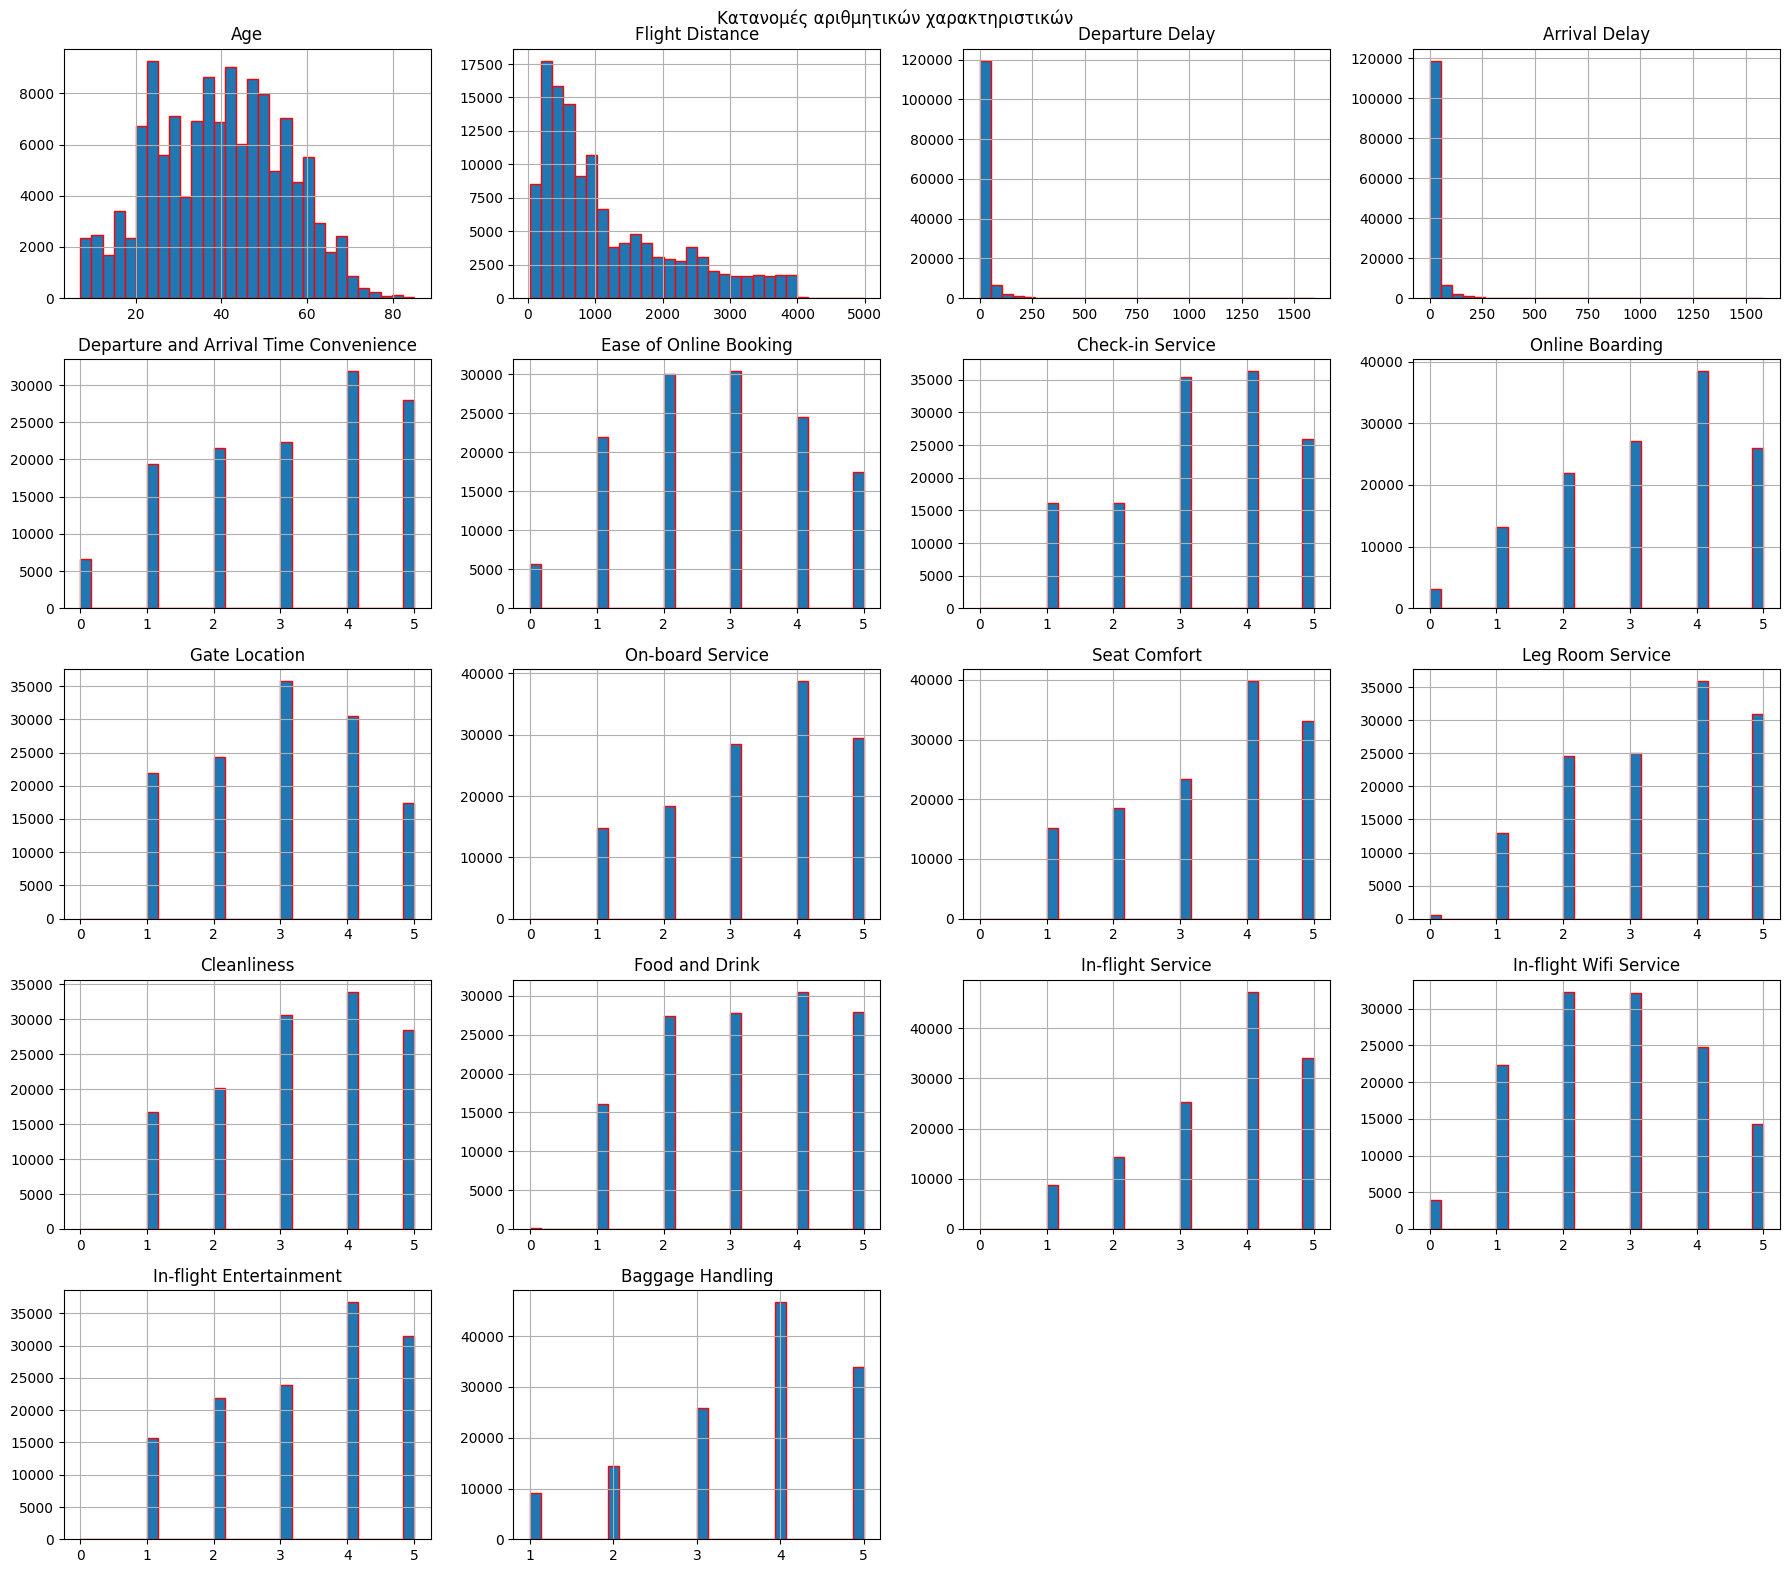

In [ ]:
#Για τον διαχωρισμό των αριθμηρικών τίμων κανουμε το εξής
numeric_values=df.select_dtypes(include="number").columns.drop("ID",errors="ignore")
#Histogram για αυτές
df[numeric_values].hist(figsize=(18, 16), bins=30, edgecolor="red")
plt.suptitle("Κατανομές αριθμητικών χαρακτηριστικών")
plt.tight_layout()
plt.show()

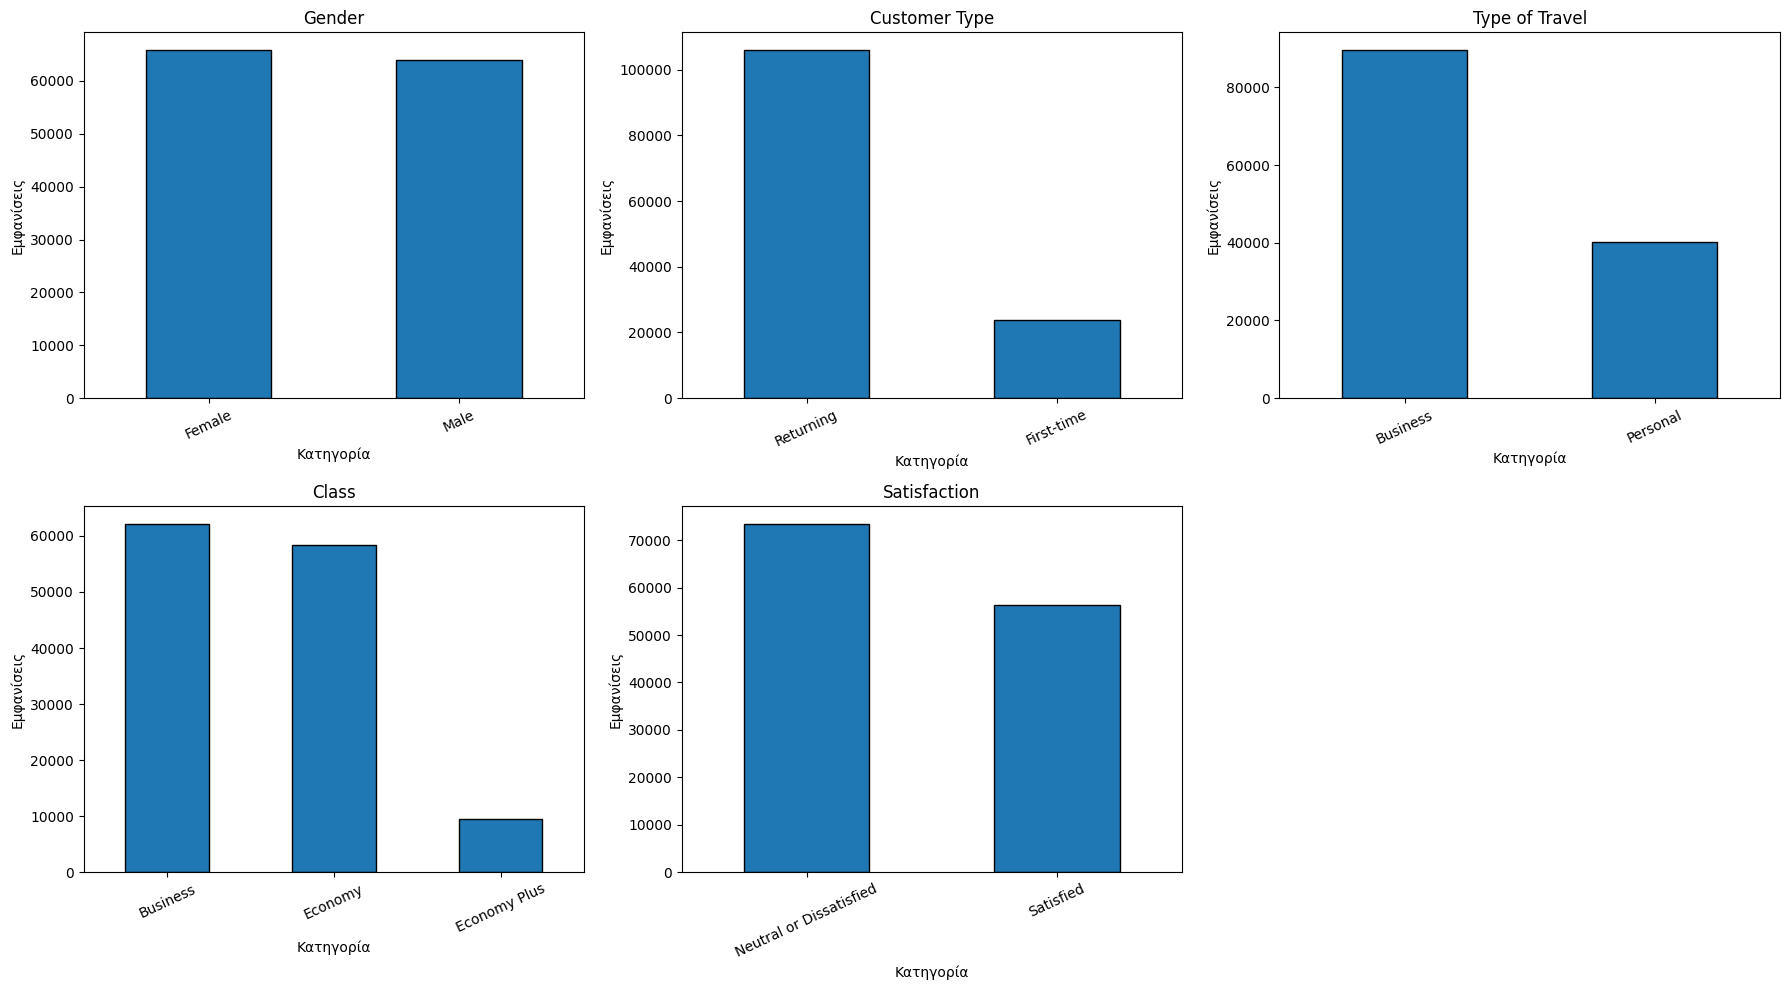

In [ ]:
#Διαλέγουμε τις κατηγορηκές τίμες απο το df μας
categorical_values = df.select_dtypes(include="object").columns

#Δημιουργούμε ένα σχήματα με υπογραφήματα
ncols = 3
nrows = math.ceil(len(categorical_values) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 5))
axes = axes.flatten()

#Επαναληπτική μέθοδος για να εκτυπωθούν όλα μαζί
for i, categorical in enumerate(categorical_values):
    df[categorical].value_counts().plot(kind="bar",ax=axes[i],edgecolor="black")

    axes[i].set_title(categorical)
    axes[i].set_xlabel("Κατηγορία")
    axes[i].set_ylabel("Εμφανίσεις")
    axes[i].tick_params(axis="x", rotation=25)

#Αφαίρεση των κενών υπογραφημάτων
for i in range(len(categorical_values), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

In [ ]:
#Ελέγχουμε αν θα ισορροπήσουν των κλάσεων
counts = df["Satisfaction"].value_counts()
print(counts)

Satisfaction
Neutral or Dissatisfied    73452
Satisfied                  56428
Name: count, dtype: int64


παρατηρούμε οτι οι κλάσεις δεν είναι πλήρως ισορροπημένες, καθώς η πρώτη κλάση εμφανίζεται συχνότερα από τη δεύτερη, δίοτι η μία εμφανίζετε 73452 φορές (Neutral or Dissatisfied) ένω η άλλη 56428 φορές (Satisfied)

**Ερώτημα 2**

In [ ]:
#μπορούμε να εντοπίσουμε στο dataset μας οτι οι περισσότερες κατηγορικές μεταβλητές μας είναι δυαδίκες επομενώς για τις περισσότερες απο αυτές θα τις
#κωδικοποιήσουμε με αυτον τον τρόπο ("Gender", "Customer Type", "Type of Travel", "satisfaction")
df["Gender"] = df["Gender"].map({"Female": 0,"Male": 1})
df["Customer Type"] = df["Customer Type"].map({"Returning": 0,"First-time": 1})
df["Type of Travel"] = df["Type of Travel"].map({"Personal": 0,"Business": 1})
df["Satisfaction"]=df["Satisfaction"].map({"Neutral or Dissatisfied":0,"Satisfied":1})

#όμως την κλάση Class θα κάνουμε τις κατηγορικές μεταβλητές σε μορφή binary vector (One-Hot Encoding)
df = pd.get_dummies(df, columns=["Class"], dtype=int)
# Εμφάνιση αποτελεσμάτων
print(df.head())


   ID  Gender  Age  Customer Type  Type of Travel  Flight Distance  \
0   1       1   48              1               1              821   
1   2       0   35              0               1              821   
2   3       1   41              0               1              853   
3   4       1   50              0               1             1905   
4   5       0   49              0               1             3470   

   Departure Delay  Arrival Delay  Departure and Arrival Time Convenience  \
0                2            5.0                                       3   
1               26           39.0                                       2   
2                0            0.0                                       4   
3                0            0.0                                       2   
4                0            1.0                                       3   

   Ease of Online Booking  ...  Cleanliness  Food and Drink  \
0                       3  ...            5          

**Ερώτημα 3**

In [ ]:
from sklearn.model_selection import train_test_split
#Διαχωρίζουμε τα χαρακτηριστικά X και y
X_df = df.drop(columns=["Satisfaction", "ID"], errors="ignore")
y = df["Satisfaction"].to_numpy()
#Κρατάμε τα ονόματα των χαρακτηριστικών
numeric_val = X_df.select_dtypes(include=np.number).columns
#Διαχωρισμός σε train (70%) και test (30%)
X_train_df, X_test_df, y_train, y_test = train_test_split(X_df, y, test_size=0.30, random_state=0)
print("X_train:", X_train_df.shape) #δεν θέλουμε ουσιαστικά το Satisfaction
print("X_test:", X_test_df.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (90916, 24)
X_test: (38964, 24)
y_train: (90916,)
y_test: (38964,)


**Ερώτημα 4**

Η κανονικοποίηση είναι απαραίτητη επειδή οι αριθμητικές μεταβλητές έχουν διαφορετικές κλίμακες για παράδειγμα οπως το Age 0-100 και το Flight Distance ~ 800 - 800> ,ακόμα και άλλες μεταξύ τους.Επομένως είναι αναγκάια μια κανονικοποίηση , αρα θα κάνουμε χρήση με StandardScaler όπου μετατρέπει κάθε αριθμητικό χαρακτηριστικό ώστε να έχει μέσο όρο περίπου 0 και τυπική απόκλιση 1.

In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
#Δημιουργία του scaler
standardscaler = StandardScaler()
# Κανονικοποίηση μόνο των αριθμητικών στηλών
X_train_df[numeric_val] = X_train_df[numeric_val].astype(float)
X_test_df[numeric_val] = X_test_df[numeric_val].astype(float)

X_train_df.loc[:, numeric_val] = standardscaler.fit_transform(X_train_df[numeric_val])
X_test_df.loc[:, numeric_val] = standardscaler.transform(X_test_df[numeric_val])
# Μετατροπή σε NumPy arrays
X_train = X_train_df.to_numpy()
X_test = X_test_df.to_numpy()

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)



X_train: (90916, 24)
X_test: (38964, 24)
y_train: (90916,)
y_test: (38964,)


**Ερώτημα 5**

Σε μία for loop, δοκιμάστε 12 συνδυασμούς του k ( k=3,5,15,51, 151, sqrt(N))

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.impute import SimpleImputer
import pandas as pd
import math
#Συμπλήρωση κενών τιμών
imputer = SimpleImputer(strategy="mean")
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

#Τιμές του k και βάρη γειτόνων
N = len(X_train)
k_values = [3, 5, 15, 51, 151, int(math.sqrt(N))]
weights_values = ["uniform", "distance"]

results = []

#Δοκιμή όλων των συνδυασμών
for k in k_values:
    for weight in weights_values:
        knn = KNeighborsClassifier(
            n_neighbors=k,
            weights=weight,
            metric="euclidean",
            n_jobs=-1
        )

        knn.fit(X_train, y_train)

        train_acc = accuracy_score(y_train, knn.predict(X_train))
        test_acc = accuracy_score(y_test, knn.predict(X_test))

        results.append([k, weight, train_acc, test_acc])

#Εμφάνιση αποτελεσμάτων σε πίνακα
results_df = pd.DataFrame(
    results,
    columns=["k", "weights", "Train Accuracy", "Test Accuracy"]
)

print(results_df.round(4))

#Καλύτερος συνδυασμός
print("\nΚαλύτερος συνδυασμός:")
print(results_df.loc[results_df["Test Accuracy"].idxmax()])




      k   weights  Train Accuracy  Test Accuracy
0     3   uniform          0.9580         0.9245
1     3  distance          1.0000         0.9244
2     5   uniform          0.9484         0.9276
3     5  distance          1.0000         0.9277
4    15   uniform          0.9335         0.9273
5    15  distance          1.0000         0.9279
6    51   uniform          0.9223         0.9184
7    51  distance          1.0000         0.9196
8   151   uniform          0.9102         0.9076
9   151  distance          1.0000         0.9095
10  301   uniform          0.9032         0.9008
11  301  distance          1.0000         0.9016

Καλύτερος συνδυασμός:
k                       15
weights           distance
Train Accuracy         1.0
Test Accuracy     0.927882
Name: 5, dtype: object
